# 7.3 Multivariate Statistics

**Goal:** reason about joint distributions, Gaussian conditioning, multivariate distance, PCA, and MANOVA.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Bayesian Statistics](1_Bayesian-Statistics.ipynb)
2. [Parameter Estimation](2_Parameter-Estimation.ipynb)
3. [Multivariate Statistics](3_Multivariate-Statistics.ipynb)
4. [Resampling Methods](4_Resampling-Methods.ipynb)
5. [Experimental Design](5_Experimental-Design.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Multivariate Distributions and Joint Probability Distributions

A joint distribution specifies probabilities for a random vector, including its dependence structure. Marginal distributions are obtained by summing/integrating over other components. They do not determine the joint distribution without dependence information. Conditional distributions restrict and renormalize using the relevant marginal, when defined.

**Worked example:** two binary variables may each be Bernoulli(.5) but be independent, perfectly equal, or perfectly opposite. All three cases share marginals and differ in joint probabilities. A product of marginals is justified only under independence.

In [2]:
joint=np.array([[.4,.1],[.1,.4]])
print("Row/column marginals:",joint.sum(1),joint.sum(0))
print("P(second=1 | first=1):",joint[1,1]/joint[1].sum())
assert np.isclose(joint.sum(),1)

Row/column marginals: [0.5 0.5] [0.5 0.5]
P(second=1 | first=1): 0.8


## 2. Multivariate Normal Distribution

For positive-definite Σ, $X\sim N_p(\mu,\Sigma)$ has density proportional to $|\Sigma|^{-1/2}\exp[-(x-\mu)^T\Sigma^{-1}(x-\mu)/2]$. Singular Gaussian distributions exist on lower-dimensional spaces but do not have an ordinary full-dimensional density.

Gaussian marginals are normal. For a partition (X₁,X₂), the conditional mean is $\mu_1+\Sigma_{12}\Sigma_{22}^{-1}(x_2-\mu_2)$ and conditional covariance $\Sigma_{11}-\Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}$. Within a jointly Gaussian model, zero covariance implies independence; this equivalence does not hold for arbitrary distributions.

In [3]:
mu=np.array([0.,1.]);Sigma=np.array([[4.,1.2],[1.2,1.]])
conditional_mean=mu[0]+Sigma[0,1]/Sigma[1,1]*(2-mu[1])
conditional_var=Sigma[0,0]-Sigma[0,1]**2/Sigma[1,1]
print("X1 | X2=2 mean/variance:",conditional_mean,conditional_var)
points=rng.multivariate_normal(mu,Sigma,size=250)

X1 | X2=2 mean/variance: 1.2 2.56


## 3. Covariance Matrices and Correlation Matrices

Covariance carries product units; correlation standardizes by SDs. Both are symmetric positive semidefinite when computed coherently from a common dataset, and constant features have undefined correlations. High-dimensional covariance can be singular or noisy; shrinkage or dimensionality reduction may be necessary.

**Mahalanobis distance** is $d(x)=\sqrt{(x-\mu)^T\Sigma^{-1}(x-\mu)}$. It accounts for scale and correlations, unlike raw Euclidean distance. For a known nonsingular Gaussian model, squared distance is χ²ₚ. Estimating μ and Σ from the same data changes reference calibration; do not apply a known-parameter threshold automatically to in-sample fitted distances.

Known-model squared-distance 95% cutoff: 5.99146454710798
Sample fraction above it: 0.052


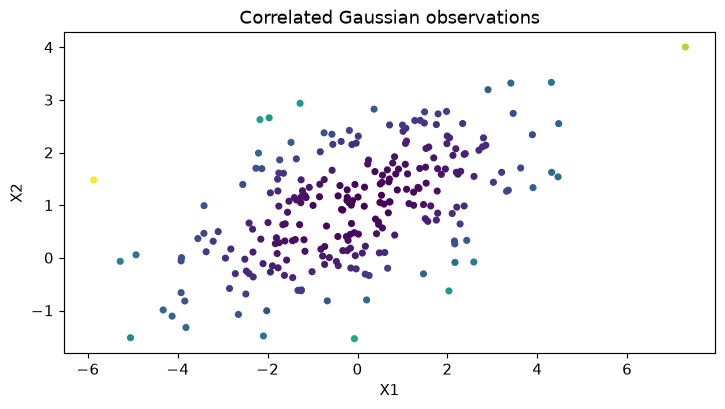

In [4]:
centered=points-mu
squared=np.einsum('ni,in->n',centered,np.linalg.solve(Sigma,centered.T))
print("Known-model squared-distance 95% cutoff:",stats.chi2.ppf(.95,df=2))
print("Sample fraction above it:",np.mean(squared>stats.chi2.ppf(.95,2)))
fig,ax=plt.subplots();ax.scatter(points[:,0],points[:,1],c=squared,cmap="viridis",s=15)
ax.set(title="Correlated Gaussian observations",xlabel="X1",ylabel="X2");fig.tight_layout();plt.show()

## 4. PCA as Multivariate Feature Analysis

PCA finds orthogonal directions of greatest sample variance: eigenvectors of a covariance matrix, with eigenvalues measuring projected variance. Center data and decide whether scaling is scientifically appropriate. Covariance PCA and standardized/correlation PCA answer different questions. High variance does not guarantee predictive importance, fairness, or causal relevance.

Fit means, scales, and component directions on training data only. Reconstruction of held-out observations uses those fitted quantities; fitting PCA on all data leaks information about the evaluation distribution.

In [5]:
center=points.mean(0);cov=np.cov(points,rowvar=False)
eigenvalues,vectors=np.linalg.eigh(cov);order=np.argsort(eigenvalues)[::-1]
components=vectors[:,order];scores=(points-center)@components
print("Explained variance proportions:",eigenvalues[order]/eigenvalues.sum())
assert np.allclose(components.T@components,np.eye(2))

Explained variance proportions: [0.86668622 0.13331378]


## 5. Multivariate Analysis of Variance (MANOVA)

MANOVA compares group mean **vectors** across several outcomes. Classical models assume independent observations, multivariate normal errors within groups, and a common covariance. Construct within-group error matrix E and between-group hypothesis matrix H; Wilks' lambda is |E|/|E+H|. Other statistics include Pillai's trace and Hotelling–Lawley trace. A multivariate rejection does not identify individual outcomes or contrasts; follow-up inference needs planning/multiplicity control.

The code computes Wilks' lambda for three synthetic groups as a descriptive test statistic. It deliberately does not invent a general F p-value: reference approximations depend on dimensions and design. A two-group multivariate mean comparison has a Hotelling T² formulation under its own sample-size and covariance assumptions. Near-singular E, small samples, outliers, and unequal covariances require special care.

In [6]:
groups=[rng.multivariate_normal([j,.4*j],np.eye(2),size=30) for j in range(3)]
grand=np.concatenate(groups).mean(0)
E=sum((g-g.mean(0)).T@(g-g.mean(0)) for g in groups)
H=sum(len(g)*np.outer(g.mean(0)-grand,g.mean(0)-grand) for g in groups)
sign_e,log_e=np.linalg.slogdet(E);sign_t,log_t=np.linalg.slogdet(E+H)
wilks=np.exp(log_e-log_t)
print("MANOVA Wilks lambda (statistic only):",wilks)
assert sign_e>0 and sign_t>0 and 0<wilks<=1

MANOVA Wilks lambda (statistic only): 0.6151589153215885


## AI/ML application and interpretation

Use joint models and multivariate distances for anomaly analysis, Gaussian classification, PCA, and multiple-outcome experiments. Verify nonsingularity and independent units. Comparing many outcome-wise tests as if they were one MANOVA changes the hypotheses and multiplicity, and fitting an anomaly reference on contaminated data can mask anomalies.

### A fully calibrated two-group multivariate comparison

For two independent multivariate-normal groups with common positive-definite covariance, pooled covariance Sₚ and p outcomes, Hotelling's two-sample statistic is T²=(n₁n₂/N)(x̄₁−x̄₂)ᵀSₚ⁻¹(x̄₁−x̄₂), where N=n₁+n₂. Under equality of mean vectors, F=[(N−p−1)/(p(N−2))]T² has an F distribution with p and N−p−1 degrees of freedom, with adequate sample size and rank. This is the two-group MANOVA case, not a formula for an arbitrary number of groups. It supplies an actual p-value while retaining the assumptions stated above.

In [7]:
g1,g2=groups[:2]
n1,n2=len(g1),len(g2);N=n1+n2;dimension=g1.shape[1]
pooled=((g1-g1.mean(0)).T@(g1-g1.mean(0))+(g2-g2.mean(0)).T@(g2-g2.mean(0)))/(N-2)
difference=g1.mean(0)-g2.mean(0)
T2=n1*n2/N*difference@np.linalg.solve(pooled,difference)
F=(N-dimension-1)/(dimension*(N-2))*T2
print("Two-group Hotelling T2:",T2,"F:",F,"p:",stats.f.sf(F,dimension,N-dimension-1))

Two-group Hotelling T2: 18.62400713522308 F: 9.151451781963065 p: 0.00035751914459378767


## Practice

1. Do Gaussian marginals alone imply a jointly Gaussian vector?
2. What changes in a conditional Gaussian distribution after observing another component?
3. Why can Euclidean distance misidentify unusual points with correlated features?
4. Does MANOVA rejection identify which individual mean differs?

## Solutions

1. No. Dependence can produce a non-Gaussian joint distribution with normal marginals.
2. Both the mean and covariance generally change according to the block-matrix formulas.
3. It ignores scale and covariance orientation; deviations along a low-variance direction may be more unusual.
4. No. It is multivariate/omnibus; use planned follow-up contrasts and appropriate error control.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](4_Resampling-Methods.ipynb).